# Tensor block QR: sanity checks and structure plots

Python port of the MATLAB live script `tensorqr_notebook.mlx`, using the `blockrr` implementations
(`blockrr.algorithm2`, `blockrr.tensor`) in place of the MATLAB functions.

| MATLAB | Python (`blockrr`) |
|---|---|
| `tensorqr(A, k)` | `algorithm2(A0u, b, k, variant="a")` |
| `tensorqr_Ws(A, k)` | `algorithm2(A0u, b, k, variant="b")` |
| `tensorqr_singleW(A, k)` | `algorithm2(A0u, b, k, variant="c")` |
| `unfold1`, `mode3`, `stack3` | `tensor.unfold1`, `tensor.mode3`, `tensor.stack3` |
| `starM(A, B, M)` | `tensor.mprod(A, B, M)` |

Conventions (as in `mode3` / `starM`):
* `X x_3 B` maps every tube `t` to `B t` (= right-multiplies each lateral slice by `B'`).
* `a *_M b = M^{-1}( (M a) .* (M b) )`; `*_I` is the facewise product.
* `unfold1` keeps blocks together: (0-based) column index `j*b + l`.
* `P, Q, R` are built with `x_3 W` (no transpose); the star product uses `M = W'`.
* Entries with `value <= tol` count as zeros in the spy plots.

Notes on the port: indices are 0-based in code, but pivots are printed 1-based to match the MATLAB output.
`algorithm2` returns a result object (`.order`, `.Q`, `.R`, `.W`) rather than a tuple, and its `W` is always `b x n x b`
(for variant "c" all `n` slices are equal, so `W[:, 0, :]` is MATLAB's single `b x b` matrix `W`).
NumPy's random stream differs from MATLAB's `randn`, so the random tensor (and hence the pivots) will not be identical to the MATLAB run.

## 0. Setup

In [29]:
import numpy as np
import matplotlib.pyplot as plt
import sys

sys.path.insert(1, '../')

from blockrr import tensor
from blockrr.tensor import unfold1, mode3, stack3, mprod
from blockrr.algorithm2 import algorithm2
import matplotlib.patches as patches

m, n, b, k = 18, 6, 3, 5          # need k*b <= m.  k < n: only the first k blocks are processed

seed = 1; tol = 1e-10
rng = np.random.default_rng(seed)

A0  = rng.standard_normal((m, n, b))   # input tensor (never overwritten)
A0u = unfold1(A0)                      # m x (n*b) matrix  [A_1 ... A_n]

print(f'A0 is {A0.shape[0]} x {A0.shape[1]} x {A0.shape[2]};  unfolded: {A0u.shape[0]} x {A0u.shape[1]};  '
      f'k = {k} (k*b = {k*b} <= m = {m})')

A0 is 18 x 6 x 3;  unfolded: 18 x 18;  k = 5 (k*b = 15 <= m = 18)


## 1. Run the three algorithms

In [30]:
def mat2str(p):                      # print a 0-based permutation 1-based, like MATLAB's mat2str
    return '[' + ' '.join(str(int(i) + 1) for i in p) + ']'

# compress=False: run on A0u exactly as given (it is square, so nothing would be compressed anyway)
res1 = algorithm2(A0u, b, k, variant="a", compress=False)
res2 = algorithm2(A0u, b, k, variant="b", compress=False)
res3 = algorithm2(A0u, b, k, variant="c", compress=False)

p1, Q1, R1      = res1.order, res1.Q, res1.R
p2, Q2, R2, W2  = res2.order, res2.Q, res2.R, res2.W     # W2: b x n x b
p3, Q3, R3, W3  = res3.order, res3.Q, res3.R, res3.W     # W3: b x n x b, all slices equal
W3 = W3[:, 0, :]                                         # the single b x b matrix W

R1u = unfold1(R1);  R2u = unfold1(R2);  R3u = unfold1(R3)
print('\n== Pivots (block permutation) ==')
print(f'  Alg 1: {mat2str(p1)}\n  Alg 2: {mat2str(p2)}\n  Alg 3: {mat2str(p3)}')
print('\nChecking orthogonality for each algorithm:')
for name, Q in (('Alg 1', Q1), ('Alg 2', Q2), ('Alg 3', Q3)):
    print(f' {name} ||Q^T*Q - I||: {np.linalg.norm(Q.T @ Q - np.eye(m), 2):e}')


== Pivots (block permutation) ==
  Alg 1: [2 5 4 1 3 6]
  Alg 2: [2 5 4 1 3 6]
  Alg 3: [2 5 4 1 3 6]

Checking orthogonality for each algorithm:
 Alg 1 ||Q^T*Q - I||: 1.262502e-15
 Alg 2 ||Q^T*Q - I||: 1.202332e-15
 Alg 3 ||Q^T*Q - I||: 1.202332e-15


## 2. Algorithm 1 (tensorqr): identity and structure


== Algorithm 1: A(:,pi,:) *_I-factorization ==
 Alg 1 ||A *_I stack(I(:,pi)) - stack(Q) *_I R||_F: 8.875989e-15


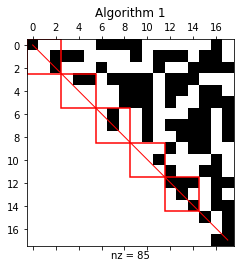

In [31]:
print('\n== Algorithm 1: A(:,pi,:) *_I-factorization ==')
I = np.eye(n)
LHS = mprod(A0, stack3(I[:, p1], b), np.eye(b))
RHS = mprod(stack3(Q1, b), R1, np.eye(b))
print(f' Alg 1 ||A *_I stack(I(:,pi)) - stack(Q) *_I R||_F: {np.linalg.norm(LHS - RHS):e}')

fig = plt.figure(figsize=(11, 3.8)); plt.title('Algorithm 1')
plt.spy(R1u > tol); plt.xlabel(f'nz = {np.count_nonzero(R1u > tol)}')
N = R1u.shape[1]
ax = plt.gca()

# red diagonal line
ax.plot([0, N - 1], [0, N - 1], color='red', linewidth=1)

# red squares around the diagonal b x b blocks of the first k block columns
for t in range(k):
    ax.add_patch(patches.Rectangle((t*b - 0.5, t*b - 0.5), b, b,
                                   fill=False, edgecolor='red', linewidth=1.5))

ax.set_xlim(-0.5, N - 0.5); ax.set_ylim(N - 0.5, -0.5)   # keep the full matrix in view
plt.show()

## 3. Algorithm 2 (tensorqr_Ws): slice-wise identity and structure


== Algorithm 2: slice-wise W ==
 Alg 2, Slice 1 ||A *_Wj P(:,j,:) - Qj *_Wj R(:,j,:)||_F: 3.876874e-15
 Alg 2, Slice 2 ||A *_Wj P(:,j,:) - Qj *_Wj R(:,j,:)||_F: 1.064147e-14
 Alg 2, Slice 3 ||A *_Wj P(:,j,:) - Qj *_Wj R(:,j,:)||_F: 8.341304e-15
 Alg 2, Slice 4 ||A *_Wj P(:,j,:) - Qj *_Wj R(:,j,:)||_F: 6.167974e-15
 Alg 2, Slice 5 ||A *_Wj P(:,j,:) - Qj *_Wj R(:,j,:)||_F: 7.215989e-15
 Alg 2, Slice 6 ||A *_Wj P(:,j,:) - Qj *_Wj R(:,j,:)||_F: 8.842460e-15


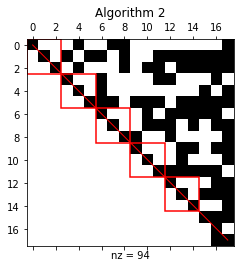

In [32]:
print('\n== Algorithm 2: slice-wise W ==')
Pt2 = stack3(I[:, p2], b);  Qt2 = stack3(Q2, b)
R2_fin = np.zeros(R2.shape)
for j in range(n):
    Wj = W2[:, j, :]                                  # b x b orthogonal matrix of slice j
    M  = Wj.T                                         # *_M matrix
    Pj = mode3(Pt2[:, j:j+1, :], Wj)
    Rj = mode3(R2[:, j:j+1, :], Wj)
    Qj = mode3(Qt2, Wj)

    LHS = mprod(A0, Pj, Wj)       # as in the MATLAB script: starM(A0, Pj, Wj)
    RHS = mprod(Qj, Rj, Wj)
    print(f' Alg 2, Slice {j+1} ||A *_Wj P(:,j,:) - Qj *_Wj R(:,j,:)||_F: {np.linalg.norm(LHS - RHS):e}')
    R2_fin[:, j:j+1, :] = Rj

fig = plt.figure(figsize=(11, 3.8)); plt.title('Algorithm 2')
plt.spy(R2u > tol); plt.xlabel(f'nz = {np.count_nonzero(R2u > tol)}')
N = R2u.shape[1]
ax = plt.gca()

# red diagonal line
ax.plot([0, N - 1], [0, N - 1], color='red', linewidth=1)

# red squares around the diagonal b x b blocks of the first k block columns
for t in range(k):
    ax.add_patch(patches.Rectangle((t*b - 0.5, t*b - 0.5), b, b,
                                   fill=False, edgecolor='red', linewidth=1.5))

ax.set_xlim(-0.5, N - 0.5); ax.set_ylim(N - 0.5, -0.5)   # keep the full matrix in view
plt.show()

## 4. Algorithm 3 (tensorqr_singleW): single-W identity and structure


== Algorithm 3: single W ==
 Alg 3 ||A *_W P - Q *_W R||_F: 1.835016e-14


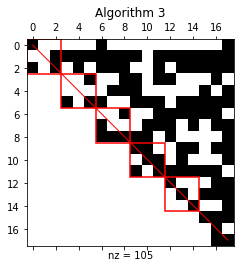

In [33]:
print('\n== Algorithm 3: single W ==')
M = W3.T
Pt3 = stack3(I[:, p3], b)
Qt3 = stack3(Q3, b)
P = mode3(Pt3, W3)
Q = mode3(Qt3, W3)
R = mode3(R3, W3)
R3_fin = R

LHS = mprod(A0, P, M)
RHS = mprod(Q, R, M)
print(f' Alg 3 ||A *_W P - Q *_W R||_F: {np.linalg.norm(LHS - RHS):e}')

fig = plt.figure(figsize=(11, 3.8)); plt.title('Algorithm 3')
plt.spy(R3u > tol); plt.xlabel(f'nz = {np.count_nonzero(R3u > tol)}')
N = R3u.shape[1]
ax = plt.gca()

# red diagonal line
ax.plot([0, N - 1], [0, N - 1], color='red', linewidth=1)

# red squares around the diagonal b x b blocks of the first k block columns
for t in range(k):
    ax.add_patch(patches.Rectangle((t*b - 0.5, t*b - 0.5), b, b,
                                   fill=False, edgecolor='red', linewidth=1.5))

ax.set_xlim(-0.5, N - 0.5); ax.set_ylim(N - 0.5, -0.5)   # keep the full matrix in view
plt.show()

## 5. Looking at structure of R tensors after mode-3 product

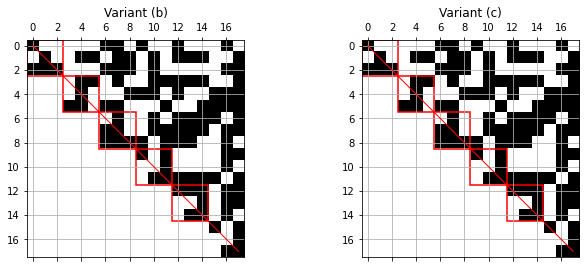

In [34]:
def mark_diagonal(ax, N, b, k):
    """Red diagonal line and red squares on the diagonal b x b blocks of the first k block columns."""
    ax.plot([0, N - 1], [0, N - 1], color='red', linewidth=1)
    for t in range(k):
        ax.add_patch(patches.Rectangle((t*b - 0.5, t*b - 0.5), b, b,
                                       fill=False, edgecolor='red', linewidth=1.5))
    ax.set_xlim(-0.5, N - 0.5); ax.set_ylim(N - 0.5, -0.5)   # keep the full matrix in view

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

# First plot
plt.sca(axes[0])
S2 = unfold1(R2_fin > tol)
plt.spy(S2)
mark_diagonal(axes[0], S2.shape[1], b, k)
plt.title('Variant (b)')
plt.grid(True)

# Second plot
plt.sca(axes[1])
S3 = unfold1(R3_fin > tol)
plt.spy(S3)
mark_diagonal(axes[1], S3.shape[1], b, k)
plt.title('Variant (c)')
plt.grid(True)
plt.show()